# Lab 13: KNN and Decision Trees
Run cells top to bottom. Dataset paths are relative to this notebook.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_digits, fetch_california_housing
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score
plt.rcParams['figure.figsize'] = (7, 4)

def classification_report_row(y, pred, average='binary'):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average=average, zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f)

def regression_report(y, pred):
    mse = mean_squared_error(y, pred)
    return dict(MAE=mean_absolute_error(y, pred), MSE=mse, RMSE=np.sqrt(mse), R2=r2_score(y, pred))


## Task 1: Telecom churn

(7043, 21) Churn
No     5174
Yes    1869
Name: count, dtype: int64 0
customerID gender  SeniorCitizen Partner Dependents  tenure PhoneService    MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies       Contract PaperlessBilling    PaymentMethod  MonthlyCharges TotalCharges Churn
7590-VHVEG Female              0     Yes         No       1           No No phone service             DSL             No          Yes               No          No          No              No Month-to-month              Yes Electronic check           29.85        29.85    No
5575-GNVDE   Male              0      No         No      34          Yes               No             DSL            Yes           No              Yes          No          No              No       One year               No     Mailed check           56.95       1889.5    No
3668-QPYBK   Male              0      No         No       2          Yes               No             DSL 

Best: {'metric': 'manhattan', 'k': 15, 'cv_accuracy': 0.7875432820436846} Test: {'accuracy': 0.7814052519517388, 'precision': 0.6050955414012739, 'recall': 0.5080213903743316, 'f1': 0.5523255813953488}


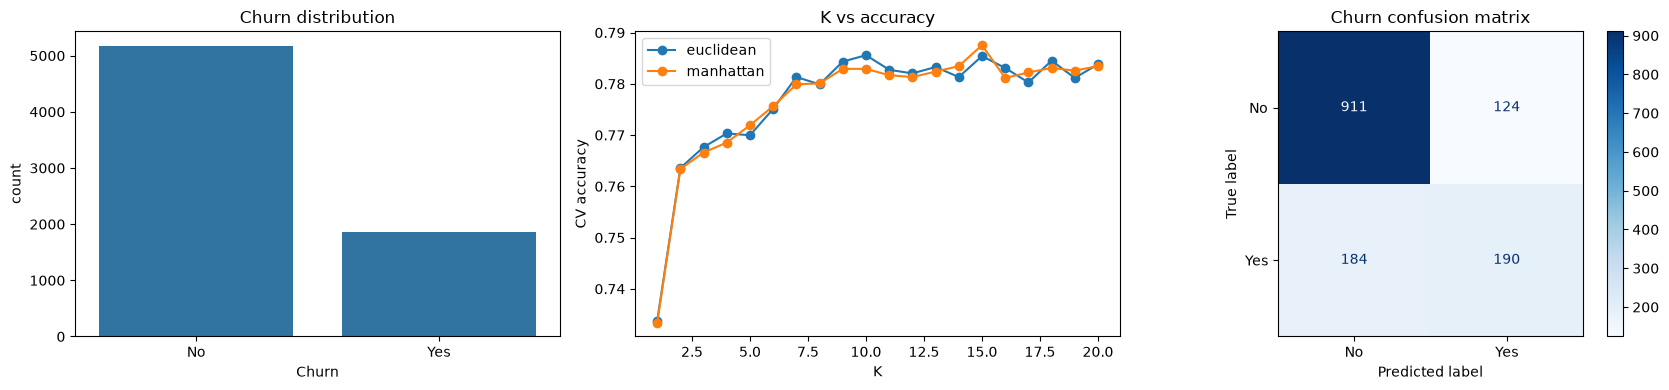

In [2]:
telco = pd.read_csv('datasets/Telco-Customer-Churn.csv')
print(telco.shape, telco['Churn'].value_counts(), telco.isna().sum().sum())
print(telco.head(3).to_string(index=False))
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
services = ['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
telco['service_count'] = telco[services].eq('Yes').sum(axis=1)
features1 = ['MonthlyCharges','tenure','TotalCharges','Contract','InternetService','PaymentMethod','service_count']
X1, y1 = telco[features1], telco['Churn'].eq('Yes').astype(int)
num1 = ['MonthlyCharges','tenure','TotalCharges','service_count']
cat1 = ['Contract','InternetService','PaymentMethod']
prep1 = ColumnTransformer([('num', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]), num1), ('cat', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]), cat1)])
X1_train, X1_test, y1_train, y1_test = train_test_split(X1,y1,test_size=.2,stratify=y1,random_state=42)
cv1 = StratifiedKFold(5, shuffle=True, random_state=42)
rows1 = []
for metric in ['euclidean','manhattan']:
    for k in range(1,21):
        model = Pipeline([('prep',prep1),('knn',KNeighborsClassifier(n_neighbors=k,metric=metric))])
        score = cross_val_score(model,X1_train,y1_train,cv=cv1,scoring='accuracy').mean()
        rows1.append((metric,k,score))
scores1 = pd.DataFrame(rows1,columns=['metric','k','cv_accuracy'])
best1 = scores1.loc[scores1.cv_accuracy.idxmax()]
model1 = Pipeline([('prep',prep1),('knn',KNeighborsClassifier(n_neighbors=int(best1.k),metric=best1.metric))]).fit(X1_train,y1_train)
pred1 = model1.predict(X1_test)
print('Best:',best1.to_dict(),'Test:',classification_report_row(y1_test,pred1))
fig, axes = plt.subplots(1,3,figsize=(17,4))
sns.countplot(data=telco,x='Churn',ax=axes[0]); axes[0].set_title('Churn distribution')
for metric, group in scores1.groupby('metric'):
    axes[1].plot(group.k,group.cv_accuracy,marker='o',label=metric)
axes[1].set(xlabel='K',ylabel='CV accuracy',title='K vs accuracy'); axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y1_test,pred1,display_labels=['No','Yes'],ax=axes[2],cmap='Blues'); axes[2].set_title('Churn confusion matrix')
plt.tight_layout(); plt.show()


### Task 1 analysis
1. Scaling prevents charges or tenure from dominating Euclidean or Manhattan distances merely because of their units.
2. A customer resembles past churners when its scaled subscription and usage features are close to theirs; their labels then dominate the neighbor vote.
3. Very small K is sensitive to noise and can overfit. Very large K smooths away local patterns and can favor the majority class.
4. Focus on **recall** for the churn class to identify as many potential churners as possible, accepting more false alarms.

## Task 2: Breast cancer decision trees

(569, 30) {1: 357, 0: 212}    mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension
0        17.99         10.38           122.8     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33            184.6      2019.0            0.1622             0.6656           0.7119   

Best parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 10} Pruning alpha: 0.013237180332208678
Test: {'accuracy': 0.9298245614035088, 'precision': 0.9444444444444444, 'recall': 0.9444444444444444, 'f1': 0.9444444444444444} ROC AUC: 0.9454365079365079
Root node: worst radius <= 16.795 goes left; otherwise right


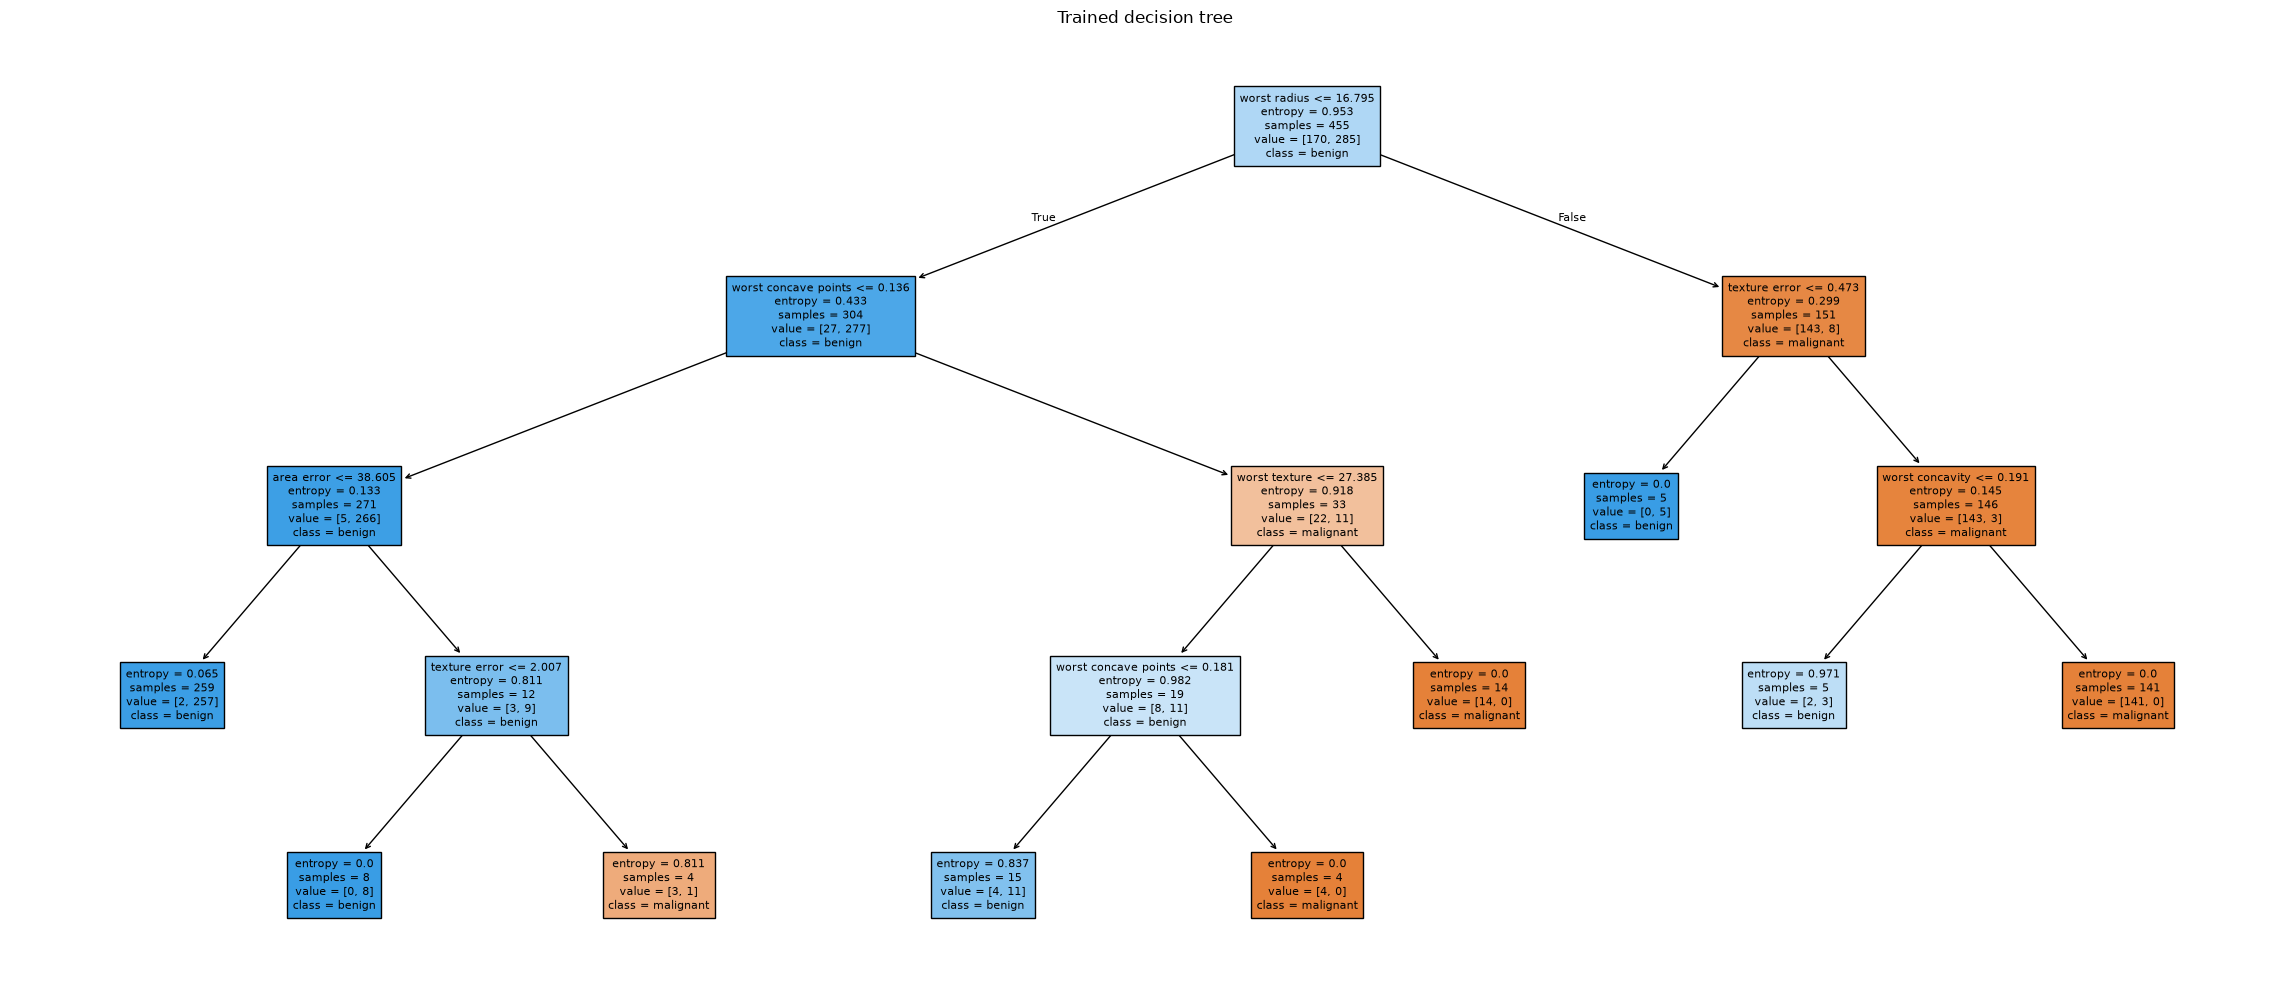

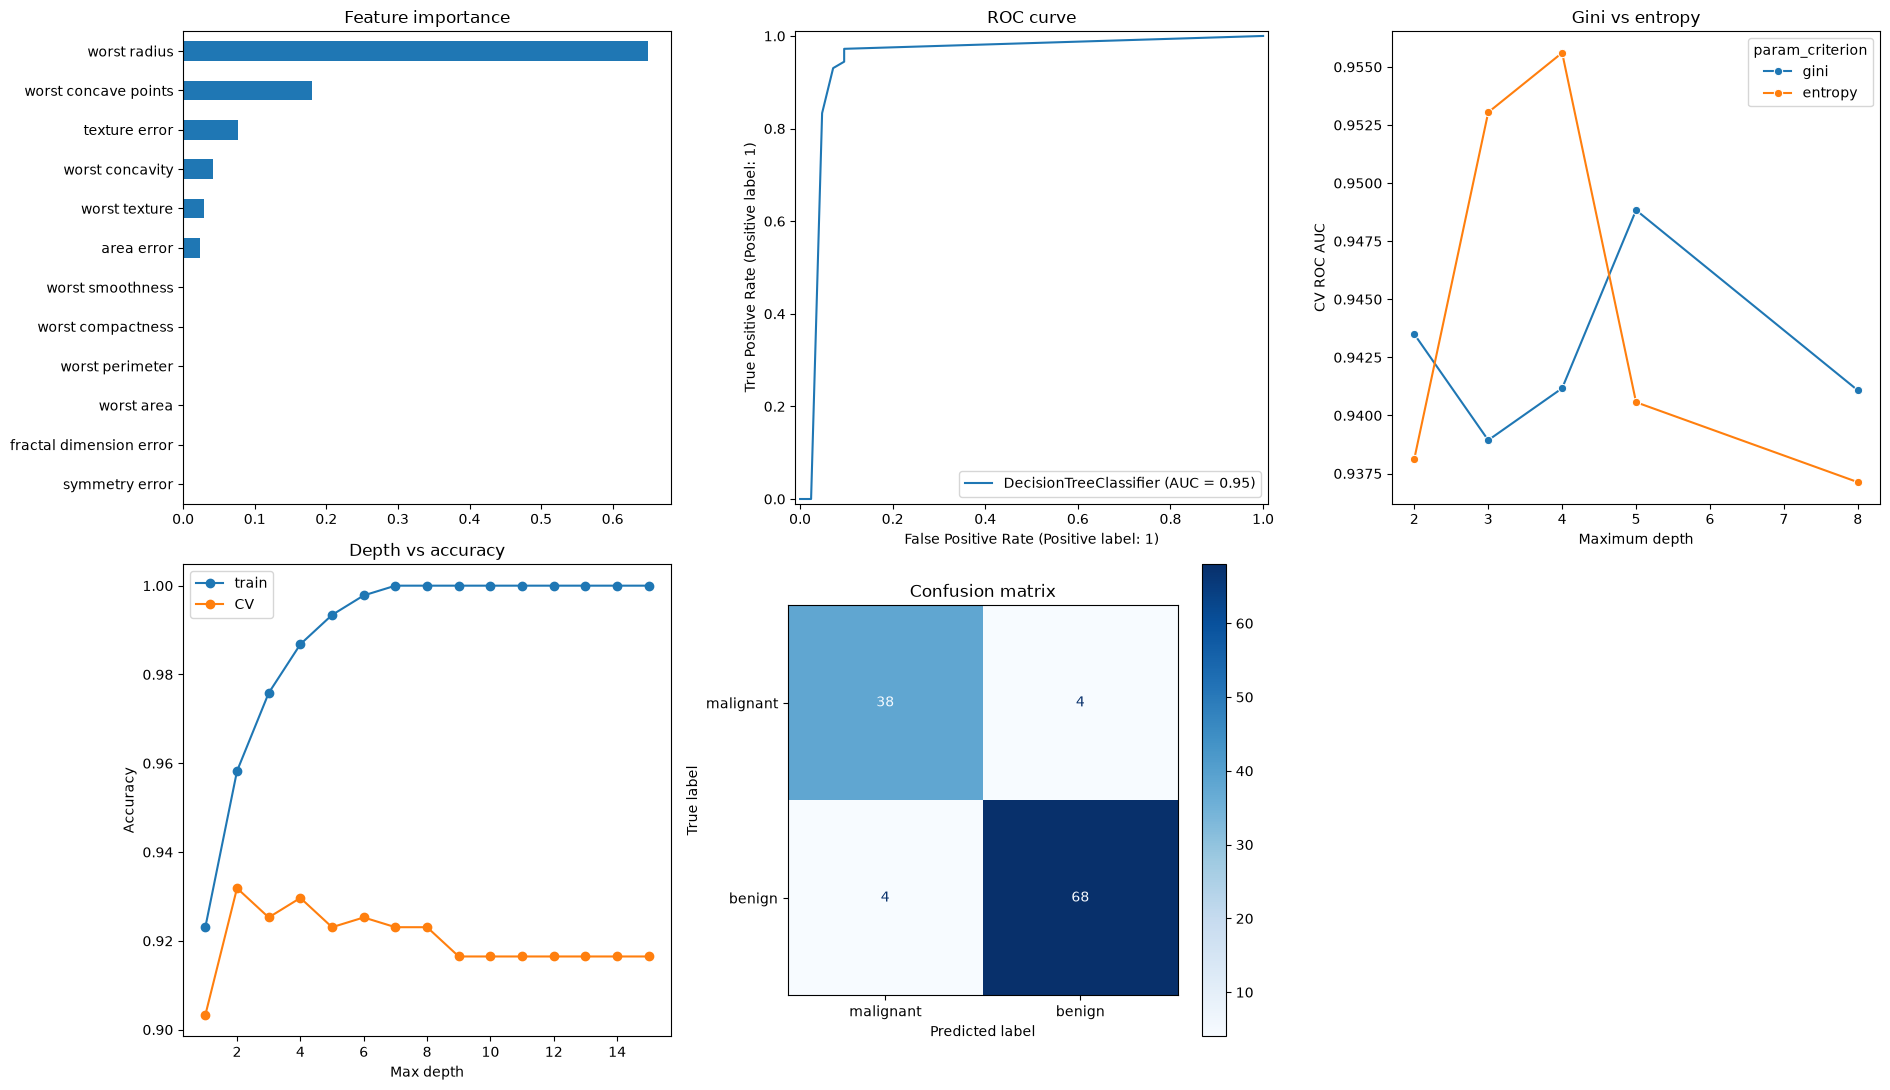

In [3]:
cancer = load_breast_cancer(as_frame=True)
X2, y2 = cancer.data, cancer.target
print(X2.shape, pd.Series(y2).value_counts().to_dict(), X2.head(3).to_string())
X2_train,X2_test,y2_train,y2_test = train_test_split(X2,y2,test_size=.2,stratify=y2,random_state=42)
cv2 = StratifiedKFold(5,shuffle=True,random_state=42)
grid2 = {'criterion':['gini','entropy'],'max_depth':[2,3,4,5,8,None], 'min_samples_split':[2,5,10], 'min_samples_leaf':[1,2,4]}
search2 = GridSearchCV(DecisionTreeClassifier(random_state=42),grid2,cv=cv2,scoring='roc_auc',n_jobs=-1).fit(X2_train,y2_train)
base2 = search2.best_estimator_
path2 = base2.cost_complexity_pruning_path(X2_train,y2_train)
alphas2 = np.unique(path2.ccp_alphas[:-1])
alpha_scores2 = [(a,cross_val_score(DecisionTreeClassifier(**{**search2.best_params_,'ccp_alpha':float(a),'random_state':42}),X2_train,y2_train,cv=cv2,scoring='roc_auc').mean()) for a in alphas2]
alpha2 = max((item for item in alpha_scores2 if item[0]>0),key=lambda item:item[1])[0]
model2 = DecisionTreeClassifier(**{**search2.best_params_,'ccp_alpha':float(alpha2),'random_state':42}).fit(X2_train,y2_train)
pred2 = model2.predict(X2_test)
print('Best parameters:',search2.best_params_,'Pruning alpha:',alpha2)
print('Test:',classification_report_row(y2_test,pred2),'ROC AUC:',roc_auc_score(y2_test,model2.predict_proba(X2_test)[:,1]))
print('Root node:',X2.columns[model2.tree_.feature[0]],'<=',round(model2.tree_.threshold[0],3),'goes left; otherwise right')
fig,tree_ax=plt.subplots(figsize=(23,10))
plot_tree(model2,feature_names=list(X2.columns),class_names=list(cancer.target_names),filled=True,fontsize=8,ax=tree_ax)
tree_ax.set_title('Trained decision tree')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,3,figsize=(19,11))
pd.Series(model2.feature_importances_,index=X2.columns).sort_values().tail(12).plot.barh(ax=axes[0,0]); axes[0,0].set_title('Feature importance')
RocCurveDisplay.from_estimator(model2,X2_test,y2_test,ax=axes[0,1]); axes[0,1].set_title('ROC curve')
results2=pd.DataFrame(search2.cv_results_)
sns.lineplot(data=results2,x='param_max_depth',y='mean_test_score',hue='param_criterion',marker='o',errorbar=None,ax=axes[0,2]); axes[0,2].set(xlabel='Maximum depth',ylabel='CV ROC AUC',title='Gini vs entropy')
depth_rows2=[]
for depth in range(1,16):
    tree=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X2_train,y2_train)
    depth_rows2.append((depth,accuracy_score(y2_train,tree.predict(X2_train)),cross_val_score(tree,X2_train,y2_train,cv=cv2,scoring='accuracy').mean()))
depth_df2=pd.DataFrame(depth_rows2,columns=['depth','train','CV']); depth_df2.plot(x='depth',y=['train','CV'],marker='o',ax=axes[1,0]); axes[1,0].set(xlabel='Max depth',ylabel='Accuracy',title='Depth vs accuracy')
ConfusionMatrixDisplay.from_predictions(y2_test,pred2,display_labels=cancer.target_names,ax=axes[1,1],cmap='Blues'); axes[1,1].set_title('Confusion matrix')
axes[1,2].axis('off')
plt.tight_layout();plt.show()


### Task 2 tree interpretation
At the root, `worst radius ≤ 16.795` sends a case left; larger values go right. The left child then tests `worst concave points ≤ 0.136`, while the right child tests `texture error ≤ 0.473`. Each terminal node predicts its majority class.

## Task 4: E-commerce customer similarity

(100, 40)        purchase_frequency  avg_order_value  spending_score  total_purchases  return_rate  cross_category_purchases
count              100.00           100.00          100.00           100.00       100.00                    100.00
mean                10.04           183.65           50.50            10.04         0.09                      1.47
std                  5.70            98.88           31.98             5.70         0.06                      1.03
min                  1.00            85.42            3.00             1.00         0.02                      0.00
25%                  5.00           105.16           17.75             5.00         0.05                      1.00
50%                 10.00           160.74           43.50            10.00         0.07                      1.00
75%                 15.00           222.79           83.25            15.00         0.12                      2.00
max                 20.00           447.96          100.00            

algorithm  k  seconds  accuracy  precision  recall     f1
  kd_tree  1   0.0012      0.30     0.2722  0.3028 0.2722
  kd_tree  3   0.0012      0.35     0.2992  0.3083 0.2917
  kd_tree  5   0.0011      0.40     0.3929  0.3639 0.3167
  kd_tree  7   0.0011      0.35     0.2681  0.3083 0.2745
  kd_tree  9   0.0012      0.35     0.2726  0.3083 0.2698
  kd_tree 11   0.0012      0.20     0.0952  0.1333 0.1111
  kd_tree 15   0.0011      0.15     0.0905  0.1222 0.1000
    brute  1   0.0010      0.30     0.2722  0.3028 0.2722
    brute  3   0.0010      0.35     0.2992  0.3083 0.2917
    brute  5   0.0010      0.40     0.3929  0.3639 0.3167
    brute  7   0.0010      0.35     0.2681  0.3083 0.2745
    brute  9   0.0010      0.35     0.2726  0.3083 0.2698
    brute 11   0.0010      0.20     0.0952  0.1333 0.1111
    brute 15   0.0011      0.15     0.0905  0.1222 0.1000
Selected K by training CV: 3 CV accuracy: 0.2875
New profiles and predictions:
 purchase_frequency  avg_order_value  spending_scor

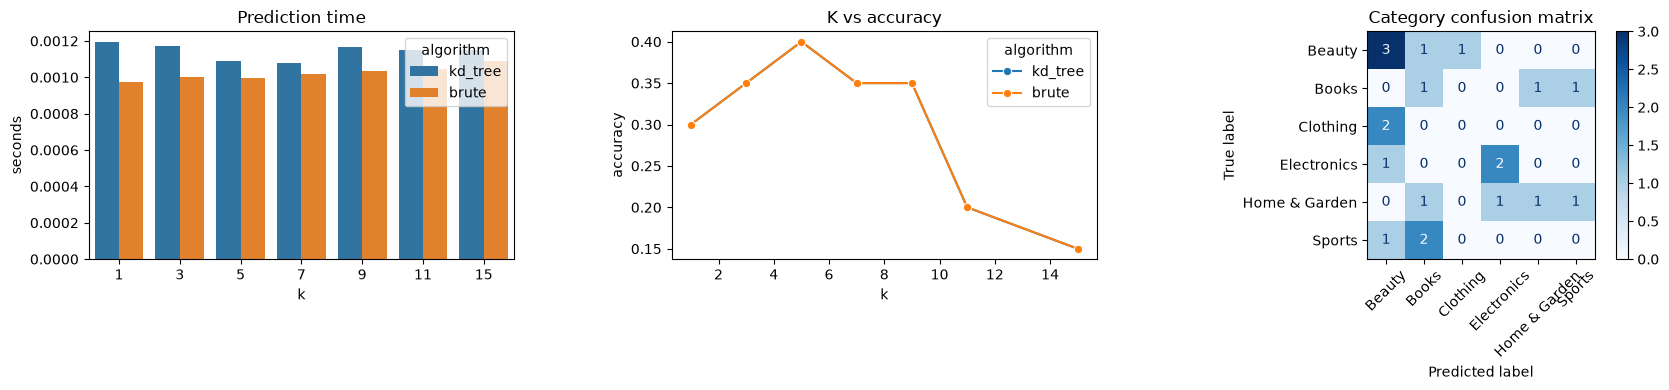

In [5]:
shop=pd.read_csv('datasets/ecommerce_customers.csv')
features4=['purchase_frequency','avg_order_value','spending_score','total_purchases','return_rate','cross_category_purchases']
X4,y4=shop[features4],shop['product_category_preference']
print(shop.shape,shop[features4].describe().round(2).to_string(),y4.value_counts().to_dict())
X4_train,X4_test,y4_train,y4_test=train_test_split(X4,y4,test_size=.2,stratify=y4,random_state=42)
impute4=SimpleImputer(strategy='median').fit(X4_train)
scale4=StandardScaler().fit(impute4.transform(X4_train))
X4_train_s=scale4.transform(impute4.transform(X4_train));X4_test_s=scale4.transform(impute4.transform(X4_test))
rows4=[];models4={}
for algorithm in ['kd_tree','brute']:
    for k in [1,3,5,7,9,11,15]:
        model=KNeighborsClassifier(n_neighbors=k,algorithm=algorithm,metric='euclidean').fit(X4_train_s,y4_train)
        times=[]
        for _ in range(20):
            start=time.perf_counter();pred=model.predict(X4_test_s);times.append(time.perf_counter()-start)
        elapsed=float(np.median(times))
        rows4.append(dict(algorithm=algorithm,k=k,seconds=elapsed,**classification_report_row(y4_test,pred,'macro')))
        models4[(algorithm,k)]=model
results4=pd.DataFrame(rows4)
cv4=StratifiedKFold(5,shuffle=True,random_state=42)
cv_scores4={k:cross_val_score(Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('knn',KNeighborsClassifier(n_neighbors=k,algorithm='kd_tree',metric='euclidean'))]),X4_train,y4_train,cv=cv4,scoring='accuracy').mean() for k in [1,3,5,7,9,11,15]}
k4=max(cv_scores4,key=cv_scores4.get)
model4=models4[('kd_tree',k4)];pred4=model4.predict(X4_test_s)
print(results4.round(4).to_string(index=False));print('Selected K by training CV:',k4,'CV accuracy:',cv_scores4[k4])
new4=pd.DataFrame([X4_train.median(),X4_train.quantile(.75)],columns=features4)
print('New profiles and predictions:')
print(new4.assign(predicted_category=model4.predict(scale4.transform(impute4.transform(new4)))).to_string(index=False))
fig,axes=plt.subplots(1,3,figsize=(17,4))
sns.barplot(data=results4,x='k',y='seconds',hue='algorithm',ax=axes[0]);axes[0].set_title('Prediction time')
sns.lineplot(data=results4,x='k',y='accuracy',hue='algorithm',marker='o',ax=axes[1]);axes[1].set_title('K vs accuracy')
ConfusionMatrixDisplay.from_predictions(y4_test,pred4,ax=axes[2],cmap='Blues',xticks_rotation=45);axes[2].set_title('Category confusion matrix')
plt.tight_layout();plt.show()


### Task 4 analysis — bonus
1. KNN scales purchasing features, measures distance to known customers, and votes among the nearest profiles.
2. KD-Tree partitions feature space, allowing some distant branches to be skipped.
3. No. Brute force may be faster for small data, high dimensions, or due to implementation overhead.
4. In high dimensions, points have less useful spatial separation, so pruning tree branches is harder.
5. Their search procedures do different amounts of work even when they return identical neighbors and labels.

## Task 6: Electricity consumption decision tree regression

(19735, 29)       T1       RH_1    T2       RH_2     T3       RH_3         T4       RH_4         T5   RH_5        T6       RH_6    T7       RH_7    T8       RH_8         T9   RH_9  T_out  RH_out  Press_mm_hg  Windspeed  Visibility
0  19.89  47.596667  19.2  44.790000  19.79  44.730000  19.000000  45.566667  17.166667  55.20  7.026667  84.256667  17.2  41.626667  18.2  48.900000  17.033333  45.53   6.60    92.0        733.5   7.000000   63.000000
1  19.89  46.693333  19.2  44.722500  19.79  44.790000  19.000000  45.992500  17.166667  55.20  6.833333  84.063333  17.2  41.560000  18.2  48.863333  17.066667  45.56   6.48    92.0        733.6   6.666667   59.166667
2  19.89  46.300000  19.2  44.626667  19.79  44.933333  18.926667  45.890000  17.166667  55.09  6.560000  83.156667  17.2  41.433333  18.2  48.730000  17.000000  45.50   6.37    92.0        733.7   6.333333   55.333333 count    19735.00
mean        97.69
std        102.52
min         10.00
25%         50.00
50%         60.00
75% 

Best: {'depth': nan, 'split': 30.0, 'leaf': 5.0, 'alpha': 0.0, 'cv_rmse': 89.37079489544162} Restricted test: {'MAE': 40.505233104600784, 'MSE': 6860.2065530795935, 'RMSE': np.float64(82.8263638769661), 'R2': 0.3144654636800511} Unrestricted test: {'MAE': 35.961489739042314, 'MSE': 7349.328604003041, 'RMSE': np.float64(85.72822524701559), 'R2': 0.2655879181150208} Pruned test: {'MAE': 44.50779235479942, 'MSE': 7668.200938522188, 'RMSE': np.float64(87.56826444849862), 'R2': 0.23372328017759414}
Top features: Press_mm_hg    0.087484
RH_1           0.066425
RH_2           0.061591
RH_7           0.061212
T3             0.060052
RH_out         0.058341
T5             0.056930
RH_9           0.048008


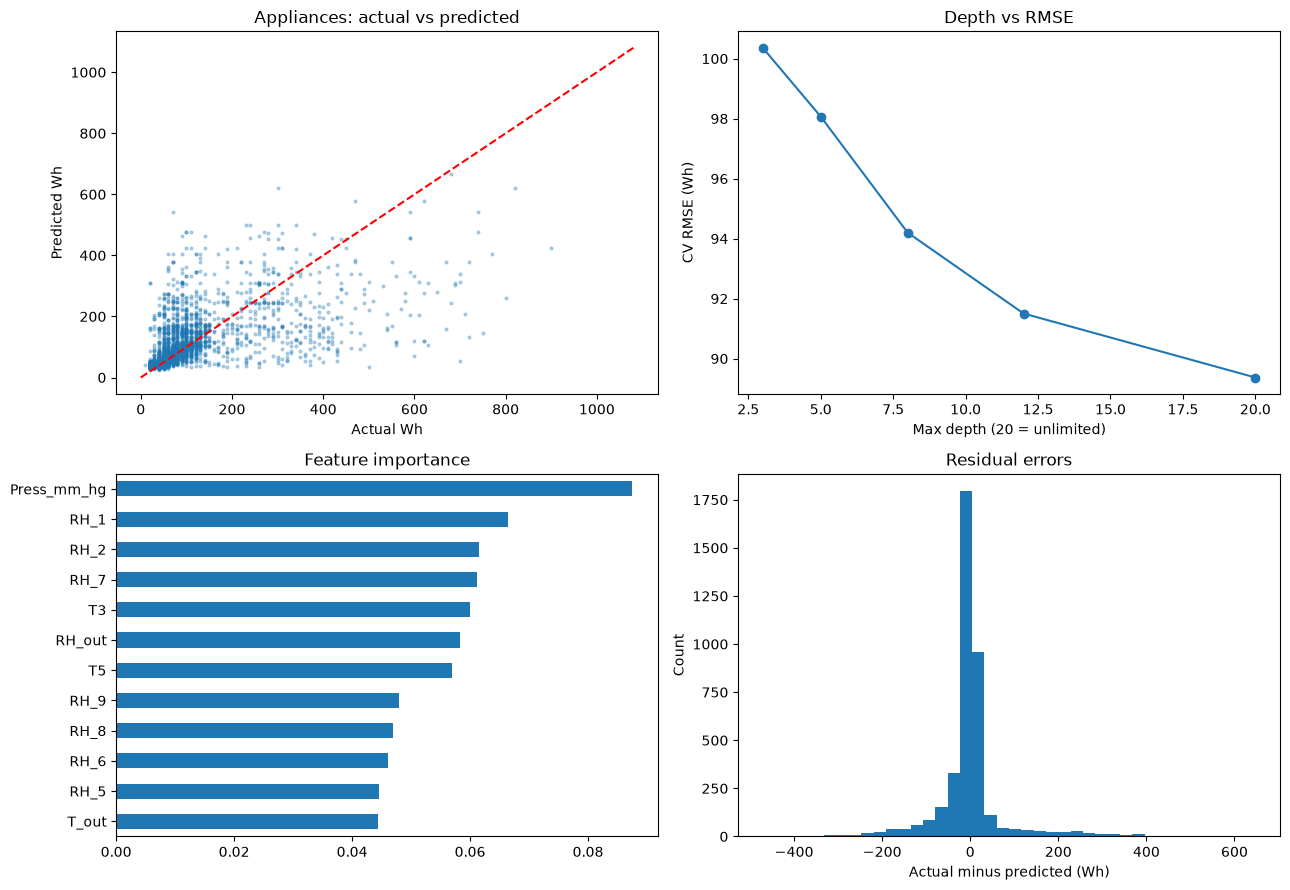

In [7]:
energy=pd.read_csv('datasets/energydata_complete.csv')
features6=[c for c in energy if c.startswith('T') or c.startswith('RH_')] + ['Press_mm_hg','Windspeed','Visibility']
features6=[c for c in features6 if c!='Tdewpoint']
X6=energy[features6].apply(pd.to_numeric,errors='coerce');y6=energy['Appliances']
print(energy.shape,X6.head(3).to_string(),y6.describe().round(2).to_string(), 'Missing:',X6.isna().sum().sum())
X6_train,X6_test,y6_train,y6_test=train_test_split(X6,y6,test_size=.2,random_state=42)
imp6=SimpleImputer(strategy='median').fit(X6_train)
X6_train_i=imp6.transform(X6_train);X6_test_i=imp6.transform(X6_test)
cv6=KFold(3,shuffle=True,random_state=42)
rows6=[]
for depth in [3,5,8,12,None]:
    for split in [2,10,30]:
        for leaf in [1,5,15]:
            for alpha in [0,1,5]:
                tree=DecisionTreeRegressor(max_depth=depth,min_samples_split=split,min_samples_leaf=leaf,ccp_alpha=alpha,random_state=42)
                rmse=-cross_val_score(tree,X6_train_i,y6_train,cv=cv6,scoring='neg_root_mean_squared_error',n_jobs=-1).mean()
                rows6.append(dict(depth=depth,split=split,leaf=leaf,alpha=alpha,cv_rmse=rmse))
results6=pd.DataFrame(rows6)
best6=results6.loc[results6.cv_rmse.idxmin()]
model6=DecisionTreeRegressor(max_depth=None if pd.isna(best6.depth) else int(best6.depth),min_samples_split=int(best6.split),min_samples_leaf=int(best6.leaf),ccp_alpha=float(best6.alpha),random_state=42).fit(X6_train_i,y6_train)
unrestricted6=DecisionTreeRegressor(random_state=42).fit(X6_train_i,y6_train)
pruned6=DecisionTreeRegressor(max_depth=12,min_samples_split=10,min_samples_leaf=5,ccp_alpha=5,random_state=42).fit(X6_train_i,y6_train)
pred6=model6.predict(X6_test_i)
print('Best:',best6.to_dict(),'Restricted test:',regression_report(y6_test,pred6),'Unrestricted test:',regression_report(y6_test,unrestricted6.predict(X6_test_i)),'Pruned test:',regression_report(y6_test,pruned6.predict(X6_test_i)))
importance6=pd.Series(model6.feature_importances_,index=features6).sort_values(ascending=False)
print('Top features:',importance6.head(8).to_string())
depth6=results6.groupby('depth',dropna=False).cv_rmse.min().reset_index()
fig,axes=plt.subplots(2,2,figsize=(13,9))
axes[0,0].scatter(y6_test,pred6,s=4,alpha=.3);axes[0,0].plot([0,y6.max()],[0,y6.max()],'r--');axes[0,0].set(xlabel='Actual Wh',ylabel='Predicted Wh',title='Appliances: actual vs predicted')
axes[0,1].plot(depth6.depth.fillna(20),depth6.cv_rmse,marker='o');axes[0,1].set(xlabel='Max depth (20 = unlimited)',ylabel='CV RMSE (Wh)',title='Depth vs RMSE')
importance6.head(12).sort_values().plot.barh(ax=axes[1,0]);axes[1,0].set_title('Feature importance')
axes[1,1].hist(y6_test-pred6,bins=40);axes[1,1].set(xlabel='Actual minus predicted (Wh)',ylabel='Count',title='Residual errors')
plt.tight_layout();plt.show()


### Task 6 analysis — bonus
1. A tree follows feature threshold splits to a leaf and predicts that leaf's average training consumption.
2. Appliances is a continuous energy value, so this is regression.
3. Atmospheric pressure, room 1 humidity, room 2 humidity, room 7 humidity, and room 3 temperature have the highest fitted feature importance. Importance measures reduction in training split error, not causal effect.
4. An unrestricted tree can create tiny leaves that fit noise and perform worse on unseen households.
5. Restricting depth reduces variance but too little depth misses meaningful patterns; the depth versus CV RMSE plot shows the tradeoff.
6. Cost-complexity pruning penalizes extra leaves through `ccp_alpha`, removing splits whose gain does not justify complexity.